# Virat Kohli's Post-2020 Test Decline: What Actually Changed

**Author:** Ritvik Y · **Format:** Test cricket only · **Data:** Himanish Ganjoo's ball-by-ball Test dataset

Companion notebook to my Medium article *"Virat Kohli's Post-2020 Decline: What Actually Changed in His Batting (Test Cricket)"*.

I split Kohli's Test career into two halves: **2016–2020** (his peak) and **2021–2025** (the downturn). The question is not just *whether* his numbers fell, but **where, against whom, and how his method changed**.

### Key findings

| | 2016–2020 | 2021–2025 |
|---|---|---|
| Median runs per innings | 40 | 20 |
| Median runs / balls vs spin (per innings) | 26 off 43 | 14 off 27 |
| Balls faced vs slow left-arm orthodox (SLA) | 843 | 821 |
| Dismissals vs SLA | 3 | 13 |
| Dismissals per 100 balls vs all spin | 0.66 | 1.49 |

1. The drop against spin was concentrated in **one bowling type, SLA**. Exposure barely changed, but runs, strike rate and survival all fell.
2. On the stumps, he **stopped driving and started defending**. Defended shots rose by roughly 18–21 percentage points through long-on, long-off and cover. His scoring moved square to **mid-wicket** (flicks), and **cover** became a dot-ball zone.
3. Outside off, he kept attacking, but his scoring behind square (cuts and steers through point and third man) halved. His runs concentrated at **cover** (29% → 52% of runs).
4. The pattern was not the same everywhere. In both England and South Africa he left far more balls outside off early in his innings. In South Africa that helped him survive the opening phase, and his full-innings median held up. In England it didn't: he was out inside his first 40 balls in 7 of 13 innings.

### Contents
1. [Setup](#1.-Setup)
2. [Data preparation](#2.-Data-preparation)
3. [Helper functions](#3.-Helper-functions)
4. [Overall output](#4.-Overall-output)
5. [Dismissal profile](#5.-Dismissal-profile)
6. [Against spin](#6.-Against-spin)
7. [SLA deep dive](#7.-SLA-deep-dive)
8. [Where did his runs go? (wagon wheels)](#8.-Where-did-his-runs-go?)
9. [Shot composition by zone](#9.-Shot-composition-by-zone)
10. [Did the pattern hold against every team?](#10.-Did-the-pattern-hold-against-every-team?)
11. [Conclusion and limitations](#11.-Conclusion-and-limitations)
12. [Appendix: data checks](#Appendix:-data-checks)

## 1. Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Wedge

# ---- Paths and constants ---------------------------------------------------
DATA_PATH = Path("TestData.csv")   # Himanish Ganjoo's Test ball-by-ball file
FIG_DIR = Path("images")                         # charts used in the article are saved here
FIG_DIR.mkdir(exist_ok=True)

PLAYER = "Virat Kohli"
P1, P2 = "2016–2020", "2021–2025"
PERIODS = [P1, P2]

# Count a dismissal only when the batter given out is Kohli himself.
# (A ball can carry a dismissal of the *non-striker*, e.g. a partner run out.)
ONLY_KOHLI_DISMISSALS = True

# ---- Plot style ----------------------------------------------------------------
COLORS = {P1: "#2a78d6", P2: "#eb6834"}
INK, MUTED = "#1f1f1f", "#6b6b6b"
WHEEL_CMAP = LinearSegmentedColormap.from_list("wheel", ["#f4f7fb", "#7fa9df"])

plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 200,
    "savefig.bbox": "tight",
    "font.size": 10.5,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#9a9a9a",
    "legend.frameon": False,
    "text.color": INK,
    "axes.labelcolor": INK,
})
pd.set_option("display.precision", 1)

## 2. Data preparation

The file covers every Test ball in the dataset. I keep 2016 onwards, take only the balls Kohli faced, and tag each ball with its period.

| Column | Meaning |
|---|---|
| `p_match`, `inns` | match id and innings number (one Kohli innings = one `p_match` + `inns` pair) |
| `batruns`, `ballfaced` | runs off the bat and whether the ball counts as faced |
| `dismissal`, `p_out` | dismissal type and the id of the batter given out |
| `bowl_kind`, `bowl_style` | pace or spin, and the specific style (RFM, OB, SLA, ...) |
| `line`, `length`, `shot` | ball-tracking style tags for each delivery |
| `wagonX`, `wagonY`, `wagonZone` | where the ball went; zones 1–8 split the field into eight sectors |

In [2]:
df = pd.read_csv(DATA_PATH, low_memory=False)
df["date"] = pd.to_datetime(df["date"])
print(f"Full dataset: {df.shape[0]:,} balls, {df.shape[1]} columns")

kohli = df[(df["bat"] == PLAYER) & (df["date"].dt.year >= 2016)].copy()
kohli["period"] = np.where(kohli["date"].dt.year <= 2020, P1, P2)

# A few deliveries are recorded with -4 runs, which is not a valid batting outcome; treat them as 0.
print("Rows with -4 runs set to 0:", int((kohli["batruns"] == -4).sum()))
kohli["batruns"] = kohli["batruns"].replace(-4, 0)

overview = kohli.groupby("period").agg(balls_faced=("ballfaced", "sum"))
overview["innings"] = kohli.drop_duplicates(["p_match", "inns"]).groupby("period").size()
overview

Full dataset: 1,601,218 balls, 57 columns
Rows with -4 runs set to 0: 1


,balls_faced,innings
period,,
2016–2020,6846.0,69
2021–2025,3811.0,61


**Data check: whose dismissal is it?** The `dismissal` column is filled on the ball a wicket falls, even when the batter out is the *non-striker* (for example a partner run out while Kohli was on strike). The cell below counts those rows. With `ONLY_KOHLI_DISMISSALS = True`, only Kohli's own dismissals are counted from here on.

In [3]:
has_dismissal = kohli["dismissal"].notna()
own = pd.to_numeric(kohli["p_out"], errors="coerce") == pd.to_numeric(kohli["p_bat"], errors="coerce")

check = (kohli[has_dismissal]
         .assign(batter_out=np.where(own[has_dismissal], "Kohli", "partner"))
         .pivot_table(index="period", columns="batter_out", values="dismissal",
                      aggfunc="count", fill_value=0))
display(check)

if ONLY_KOHLI_DISMISSALS and own[has_dismissal].any():
    kohli["out"] = has_dismissal & own
else:
    if ONLY_KOHLI_DISMISSALS:
        print("p_out could not be matched to p_bat; falling back to every dismissal row.")
    kohli["out"] = has_dismissal

# A clean dismissal column: the dismissal type only where Kohli himself was out
kohli["how_out"] = kohli["dismissal"].where(kohli["out"])

batter_out,Kohli,partner
period,,
2016–2020,63,1
2021–2025,58,3


The rows removed are all run-outs of his batting partner while Kohli was on strike:

In [4]:
partner = kohli[kohli["dismissal"].notna() & ~kohli["out"]]
partner[["period", "date", "country", "bowl", "bowl_style", "dismissal"]]

,period,date,country,bowl,bowl_style,dismissal
913233,2016–2020,2016-11-26,India,Chris Woakes,RFM,run out
1448892,2021–2025,2023-12-26,South Africa,Kagiso Rabada,RF,run out
1488117,2021–2025,2023-03-09,India,Todd Murphy,OB,run out
1571387,2021–2025,2024-10-24,India,Ajaz Patel,SLA,run out


## 3. Helper functions

Every comparison in this notebook is "2016–2020 vs 2021–2025", so the helpers below take the full Kohli frame (or a filtered slice of it) and return both periods side by side.

In [5]:
def innings_summary(d):
    # One row per innings: runs, balls, strike rate, and whether he was out.
    inns = (d.groupby(["period", "p_match", "inns"])
              .agg(runs=("batruns", "sum"), balls=("ballfaced", "sum"), out=("out", "any"))
              .reset_index())
    inns["sr"] = inns["runs"] / inns["balls"] * 100
    return inns


def median_table(d):
    # Innings count plus median runs / balls / strike rate for each period.
    inns = innings_summary(d)
    return (inns.groupby("period")
                .agg(innings=("runs", "size"), median_runs=("runs", "median"),
                     mean_runs=("runs", "mean"), median_balls=("balls", "median"),
                     median_sr=("sr", "median"))
                .reindex(PERIODS))


def style_table(d, by="bowl_style"):
    # Runs, balls, SR, dismissals and dismissals per 100 balls for each group.
    t = (d.groupby(["period", by])
           .agg(balls=("ballfaced", "sum"), runs=("batruns", "sum"), dismissals=("out", "sum"))
           .reset_index())
    t["sr"] = t["runs"] / t["balls"] * 100
    t["outs_per_100"] = t["dismissals"] / t["balls"] * 100
    return t


def share_table(d, col, by=None):
    # Percentage split of `col` within each period (and optionally within `by`).
    keys = ["period"] + ([by] if by else [])
    return (pd.crosstab([d[k] for k in keys], d[col], normalize="index")
              .mul(100).round(1))


PRETTY = {"ON_THE_STUMPS": "On stumps", "OUTSIDE_OFFSTUMP": "Outside off",
          "WIDE_OUTSIDE_OFFSTUMP": "Wide outside off", "DOWN_LEG": "Down leg",
          "WIDE_DOWN_LEG": "Wide down leg", "GOOD_LENGTH": "Good length", "FULL": "Full",
          "SHORT": "Short", "SHORT_OF_A_GOOD_LENGTH": "Short of good length",
          "YORKER": "Yorker", "FULL_TOSS": "Full toss"}

def pretty(label):
    # Readable axis labels for the dataset's upper-case tags; style codes (SLA, RFM) stay as they are.
    label = str(label)
    if label in PRETTY:
        return PRETTY[label]
    return label.replace("_", " ").capitalize() if "_" in label else label


def compare_bars(table, ax, title, ylabel="% of balls"):
    # Grouped bars, one colour per period. `table` has periods as columns.
    x = np.arange(len(table.index))
    w = 0.38
    for i, p in enumerate(PERIODS):
        vals = table[p].values if p in table else np.zeros(len(x))
        bars = ax.bar(x + (i - 0.5) * w, vals, w * 0.94, color=COLORS[p], label=p)
        ax.bar_label(bars, fmt="%.0f", fontsize=8.5, color=MUTED, padding=2)
    ax.set_xticks(x, [pretty(i) for i in table.index], rotation=0)
    ax.set_title(title, pad=22)
    ax.set_ylabel(ylabel)
    ax.margins(y=0.1)
    ax.legend(loc="lower right", bbox_to_anchor=(1, 1.0), ncol=2, fontsize=9)

### Wagon-wheel zones

The dataset splits the field into eight `wagonZone` sectors. Before drawing any wagon wheel I checked where each zone sits on the field, using the shots played into it (for a right-hander, leg glances should go fine and cuts should go square on the off side):

In [6]:
check_shots = ["LEG_GLANCE", "SWEEP_SHOT", "FLICK", "ON_DRIVE", "COVER_DRIVE", "CUT_SHOT", "STEERED"]
valid = kohli[(kohli["wagonX"] != 0) & (kohli["wagonY"] != 0) & kohli["shot"].isin(check_shots)]
pd.crosstab(valid["wagonZone"].astype(int), valid["shot"]).reindex(columns=check_shots, fill_value=0)

shot,LEG_GLANCE,SWEEP_SHOT,FLICK,ON_DRIVE,COVER_DRIVE,CUT_SHOT,STEERED
wagonZone,,,,,,,
1,74,11,102,0,2,3,2
2,32,7,399,1,3,3,0
3,1,4,1008,60,6,0,0
4,0,0,110,473,4,1,0
5,0,0,11,388,56,2,0
6,0,0,13,31,670,65,36
7,0,0,7,2,10,91,173
8,0,0,7,12,30,37,114


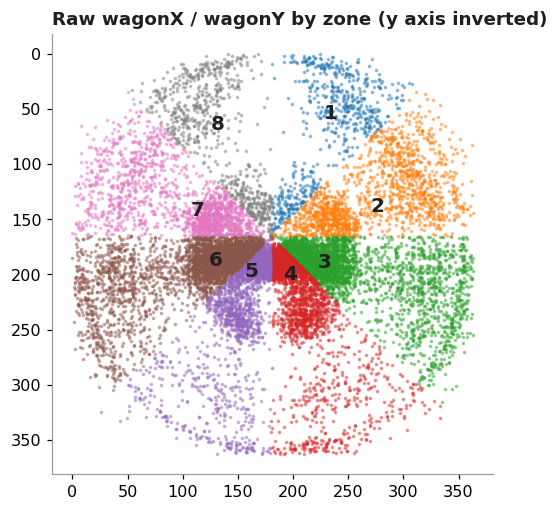

In [7]:
sample = df[df["wagonZone"] != 0].sample(min(20000, int((df["wagonZone"] != 0).sum())), random_state=1)

fig, ax = plt.subplots(figsize=(5.2, 5.2))
for z, g in sample.groupby("wagonZone"):
    ax.scatter(g["wagonX"], g["wagonY"], s=2, alpha=0.4)
    ax.text(g["wagonX"].median(), g["wagonY"].median(), int(z), fontsize=13, fontweight="bold",
            ha="center", va="center", color=INK)
ax.invert_yaxis()
ax.set_aspect("equal")
ax.grid(False)
ax.set_title("Raw wagonX / wagonY by zone (y axis inverted)")
plt.show()

Leg glances and sweeps land in zones 1–2, flicks in 2–3, on-drives in 4–5, cover drives in 6, and cuts and steers in 7–8. So, for a right-hander with the keeper at the top of the picture, the zones run **clockwise from fine leg**:

| Zone | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 |
|---|---|---|---|---|---|---|---|---|
| Region | Fine leg | Square leg | Mid-wicket | Long-on | Long-off | Cover | Point | Third man |

The wagon-wheel function below draws each zone in that position and labels it, so the region can be read directly off the chart.

In [8]:
ZONE_NAMES = {1: "Fine leg", 2: "Square leg", 3: "Mid-wicket", 4: "Long-on",
              5: "Long-off", 6: "Cover", 7: "Point", 8: "Third man"}

def zone_angles(zone):
    # Matplotlib angles (anticlockwise from 3 o'clock) for each zone, keeper at the top.
    return 90 - 45 * zone, 135 - 45 * zone


def zone_shares(d, metric="runs"):
    # % share of runs / boundary runs / dot balls by zone. Balls without wagon data are dropped.
    d = d[(d["wagonX"] != 0) & (d["wagonY"] != 0)]
    if metric == "runs":
        s = d.groupby("wagonZone")["batruns"].sum()
    elif metric == "boundaries":
        s = d[d["batruns"].isin([4, 6])].groupby("wagonZone")["batruns"].sum()
    elif metric == "dots":
        s = d[d["batruns"] == 0].groupby("wagonZone").size()
    else:
        raise ValueError(metric)
    s.index = s.index.astype(int)
    total = s.sum()
    return (s / total * 100 if total else s).reindex(range(1, 9), fill_value=0)


def draw_wheel(ax, shares, title, vmax):
    for zone in range(1, 9):
        t1, t2 = zone_angles(zone)
        pct = shares.get(zone, 0)
        ax.add_patch(Wedge((0, 0), 1, t1, t2, facecolor=WHEEL_CMAP(pct / vmax if vmax else 0),
                           edgecolor="white", linewidth=2))
        mid = np.radians((t1 + t2) / 2)
        x, y = 0.62 * np.cos(mid), 0.62 * np.sin(mid)
        ax.text(x, y + 0.07, ZONE_NAMES[zone], ha="center", va="center", fontsize=8.5, color=MUTED)
        ax.text(x, y - 0.07, f"{pct:.1f}%", ha="center", va="center", fontsize=11.5,
                fontweight="bold", color=INK)
    ax.text(0, 1.08, "keeper", ha="center", fontsize=8, color=MUTED)
    ax.text(0, -1.13, "bowler", ha="center", fontsize=8, color=MUTED)
    ax.text(-1.12, 0, "OFF", ha="center", va="center", fontsize=8, color=MUTED, rotation=90)
    ax.text(1.12, 0, "LEG", ha="center", va="center", fontsize=8, color=MUTED, rotation=-90)
    ax.set_xlim(-1.2, 1.2); ax.set_ylim(-1.2, 1.2)
    ax.set_aspect("equal"); ax.axis("off")
    ax.set_title(title, loc="center")


METRIC_LABEL = {"runs": "share of runs", "boundaries": "share of boundary runs", "dots": "share of dot balls"}

def compare_wheels(d, metric, title, filename=None):
    # Side-by-side wagon wheels for the two periods, on a shared colour scale.
    shares = {p: zone_shares(d[d["period"] == p], metric) for p in PERIODS}
    vmax = max(s.max() for s in shares.values()) or 1
    fig, axes = plt.subplots(1, 2, figsize=(11, 5.6))
    for ax, p in zip(axes, PERIODS):
        n = int((d["period"] == p).sum())
        draw_wheel(ax, shares[p], f"{p}  ({n} balls)", vmax)
    fig.suptitle(f"{title}: {METRIC_LABEL[metric]} by region", fontweight="bold", x=0.04, ha="left")
    plt.tight_layout(rect=(0, 0, 1, 0.94))
    if filename:
        fig.savefig(FIG_DIR / filename)
    plt.show()
    return pd.DataFrame(shares).rename(index=ZONE_NAMES).round(1)


def top_shots(d, zones=range(1, 9), min_pct=10):
    # For each zone: the shots that make up >= min_pct% of balls hit there, per period.
    d = d[(d["wagonX"] != 0) & (d["wagonY"] != 0) & d["shot"].notna()]
    out = {}
    for p in PERIODS:
        mix = pd.crosstab(d.loc[d["period"] == p, "wagonZone"].astype(int),
                          d.loc[d["period"] == p, "shot"], normalize="index") * 100
        out[p] = {ZONE_NAMES[z]: ", ".join(f"{s.replace('_', ' ').lower()} {v:.0f}%"
                                           for s, v in mix.loc[z].sort_values(ascending=False).items()
                                           if v >= min_pct) if z in mix.index else "–"
                  for z in zones}
    return pd.DataFrame(out)


def defended_share(d):
    # % of balls defended in each zone, per period.
    d = d[(d["wagonX"] != 0) & (d["wagonY"] != 0) & d["shot"].notna()]
    t = (d.assign(defended=d["shot"].eq("DEFENDED"))
           .groupby(["wagonZone", "period"])["defended"].mean().mul(100).unstack())
    t.index = t.index.astype(int).map(ZONE_NAMES)
    return t.reindex(columns=PERIODS)


def first_n_balls(d, n):
    # Rows in the file are NOT in ball order, so use Kohli's running balls-faced count instead
    bf = pd.to_numeric(d["cur_bat_bf"], errors="coerce")
    return d[bf <= n]

## 4. Overall output

In [9]:
median_table(kohli)

,innings,median_runs,mean_runs,median_balls,median_sr
period,,,,,
2016–2020,69,40.0,60.6,65.0,50.9
2021–2025,61,20.0,30.8,40.0,45.8


His median score per innings **halved, from 40 to 20**, and the mean fell from about 60 to about 31. The rest of the notebook looks for where that drop came from.

## 5. Dismissal profile

Where was he getting out against pace and spin, and to which bowling styles?

In [10]:
outs = kohli[kohli["out"]]
print("Dismissals per period:", outs["period"].value_counts().reindex(PERIODS).to_dict())

print("\nHow he was out (% of dismissals, by bowler type)")
display(share_table(outs, "how_out", by="bowl_kind"))

Dismissals per period: {'2016–2020': 63, '2021–2025': 58}

How he was out (% of dismissals, by bowler type)


how_out                bowled  caught  hit wicket  leg before wicket  run out
period    bowl_kind                                                          
2016–2020 pace bowler     4.5    65.9         0.0               29.5      0.0
          spin bowler     5.3    63.2         5.3               26.3      0.0
2021–2025 pace bowler     6.1    90.9         0.0                3.0      0.0
          spin bowler    24.0    32.0         0.0               36.0      8.0

In [11]:
print("Line of the dismissal ball (%)")
display(share_table(outs, "line", by="bowl_kind"))

print("Length of the dismissal ball (%)")
display(share_table(outs, "length", by="bowl_kind"))

Line of the dismissal ball (%)


line                   DOWN_LEG  ON_THE_STUMPS  OUTSIDE_OFFSTUMP  \
period    bowl_kind                                                
2016–2020 pace bowler       2.3           20.5              61.4   
          spin bowler       0.0           21.1              47.4   
2021–2025 pace bowler       0.0            4.3              78.3   
          spin bowler       5.9           35.3              58.8   

line                   WIDE_OUTSIDE_OFFSTUMP  
period    bowl_kind                           
2016–2020 pace bowler                   15.9  
          spin bowler                   31.6  
2021–2025 pace bowler                   17.4  
          spin bowler                    0.0

Length of the dismissal ball (%)


length                 FULL  GOOD_LENGTH  SHORT  SHORT_OF_A_GOOD_LENGTH
period    bowl_kind                                                    
2016–2020 pace bowler  25.0         47.7   11.4                    15.9
          spin bowler  26.3         68.4    5.3                     0.0
2021–2025 pace bowler  21.7         52.2    0.0                    26.1
          spin bowler  11.8         64.7    0.0                    23.5

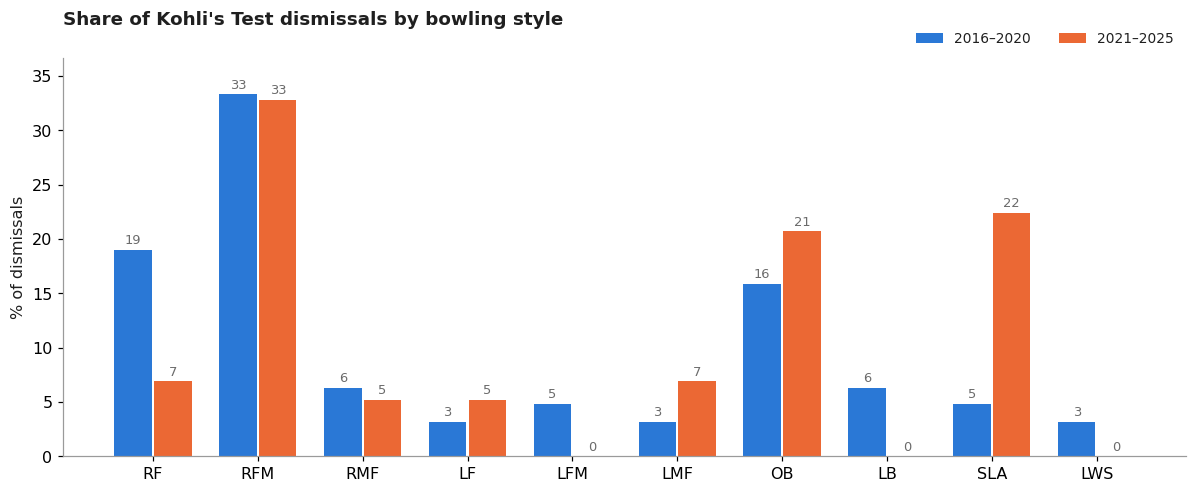

In [12]:
style_order = ["RF", "RFM", "RMF", "LF", "LFM", "LMF", "OB", "LB", "SLA", "LWS"]
style_share = share_table(outs, "bowl_style").T
style_share = style_share.reindex([s for s in style_order if s in style_share.index] +
                                  [s for s in style_share.index if s not in style_order])

fig, ax = plt.subplots(figsize=(11, 4.6))
compare_bars(style_share, ax, "Share of Kohli's Test dismissals by bowling style", ylabel="% of dismissals")
plt.tight_layout()
fig.savefig(FIG_DIR / "dismissal_share_by_bowling_style.png")
plt.show()

- **Against pace**, he was mostly caught on a good length outside off, most often to right-arm fast-medium (RFM). In 2021–2025 this became almost his only way of getting out to pace: 91% of those dismissals were caught (up from 66%), and 78% of the dismissal balls were outside off (up from 61%).
- **Against spin**, the type of dismissal changed. In 2016–2020 he was mostly caught on balls outside or wide outside off. In 2021–2025 LBW and bowled became much more common, on balls outside off or on the stumps.
- Off-spin (OB) accounted for a similar share in both periods. **The real jump was slow left-arm orthodox (SLA).**

*Bowling styles: RF / RFM / RMF = right-arm fast / fast-medium / medium-fast; LF / LFM / LMF = left-arm equivalents; OB = off break; LB = leg break; SLA = slow left-arm orthodox; LWS = left-arm wrist spin.*

## 6. Against spin

In [13]:
spin = kohli[kohli["bowl_kind"] == "spin bowler"]
median_table(spin)

,innings,median_runs,mean_runs,median_balls,median_sr
period,,,,,
2016–2020,47,26.0,38.3,43.0,58.3
2021–2025,40,14.0,20.1,27.0,44.2


Per innings against spin, his median went from **26 runs off 43 balls to 14 off 27**. He was scoring less *and* surviving less time at the crease against spin.

In [14]:
spin_styles = style_table(spin)
spin_styles.pivot(index="bowl_style", columns="period",
                  values=["balls", "runs", "sr", "dismissals"]).round(1)

balls                runs                  sr            \
period     2016–2020 2021–2025 2016–2020 2021–2025 2016–2020 2021–2025   
bowl_style                                                               
LB             708.0       NaN     477.0       NaN      67.4       NaN   
LWS            133.0       NaN     108.0       NaN      81.2       NaN   
OB            1178.0     829.0     696.0     428.0      59.1      51.6   
OB/LB           18.0      29.0      17.0      17.0      94.4      58.6   
SLA            843.0     821.0     503.0     361.0      59.7      44.0   

           dismissals            
period      2016–2020 2021–2025  
bowl_style                       
LB                4.0       NaN  
LWS               2.0       NaN  
OB               10.0      12.0  
OB/LB             0.0       0.0  
SLA               3.0      13.0

In [15]:
spin_rate = spin.groupby("period").agg(balls=("ballfaced", "sum"), dismissals=("out", "sum"))
spin_rate["dismissals_per_100_balls"] = (spin_rate["dismissals"] / spin_rate["balls"] * 100).round(2)
spin_rate.reindex(PERIODS)

,balls,dismissals,dismissals_per_100_balls
period,,,
2016–2020,2880.0,19,0.7
2021–2025,1679.0,25,1.5


- He faced almost the same number of SLA balls in both periods (**843 vs 821**), yet his SLA dismissals rose **from 3 to 13** and his strike rate fell from about 60 to 44. This is not a case of "faced more spin, got out more".
- Against off-spin, runs and strike rate fell too, but dismissals barely moved (10 to 12).
- Across all spin his dismissal rate rose from **0.66 to 1.49 per 100 balls**, and most of that increase came from SLA.

The spinners who dismissed him at least twice:

In [16]:
by_bowler = style_table(spin, by="bowl")
(by_bowler[by_bowler["dismissals"] >= 2]
 .sort_values(["period", "dismissals"], ascending=[True, False])
 .set_index(["period", "bowl"])[["balls", "runs", "sr", "dismissals"]])

balls   runs    sr  dismissals
period    bowl                                              
2016–2020 Adil Rashid         457.0  286.0  62.6           4
          Nathan Lyon         266.0  112.0  42.1           3
          Jeetan Patel        109.0   68.0  62.4           2
          Lakshan Sandakan    133.0  108.0  81.2           2
          Moeen Ali           252.0  137.0  54.4           2
2021–2025 Moeen Ali           100.0   42.0  42.0           3
          Todd Murphy         176.0   84.0  47.7           3
          Ajaz Patel           69.0   40.0  58.0           2
          Mehidy Hasan Miraz   79.0   31.0  39.2           2
          Mitchell Santner     30.0    8.0  26.7           2
          Rachin Ravindra      32.0   16.0  50.0           2

## 7. SLA deep dive

### 7.1 Where was he getting out?

Run-outs are set aside here because they are not a batting error against the bowling.

In [17]:
sla = kohli[kohli["bowl_style"] == "SLA"]
sla_outs = sla[sla["out"] & (sla["how_out"] != "run out")]

print("Non-run-out SLA dismissals:", sla_outs["period"].value_counts().reindex(PERIODS).to_dict())
print("...of which with no shot/line/length recorded:",
      sla_outs[sla_outs["shot"].isna()]["period"].value_counts().reindex(PERIODS, fill_value=0).to_dict())

sla_outs[["period", "shot", "line", "length", "how_out"]].dropna(subset=["shot"]).reset_index(drop=True)

Non-run-out SLA dismissals: {'2016–2020': 3, '2021–2025': 11}
...of which with no shot/line/length recorded: {'2016–2020': 0, '2021–2025': 5}


,period,shot,line,length,how_out
0,2016–2020,CUT_SHOT,WIDE_OUTSIDE_OFFSTUMP,GOOD_LENGTH,caught
1,2016–2020,LEFT_ALONE,OUTSIDE_OFFSTUMP,GOOD_LENGTH,bowled
2,2016–2020,CUT_SHOT,OUTSIDE_OFFSTUMP,GOOD_LENGTH,leg before wicket
3,2021–2025,DEFENDED,ON_THE_STUMPS,FULL,leg before wicket
4,2021–2025,CUT_SHOT,OUTSIDE_OFFSTUMP,SHORT_OF_A_GOOD_LENGTH,bowled
5,2021–2025,FLICK,ON_THE_STUMPS,GOOD_LENGTH,leg before wicket
6,2021–2025,FLICK,OUTSIDE_OFFSTUMP,SHORT_OF_A_GOOD_LENGTH,leg before wicket
7,2021–2025,DEFENDED,ON_THE_STUMPS,GOOD_LENGTH,bowled
8,2021–2025,DEFENDED,ON_THE_STUMPS,GOOD_LENGTH,leg before wicket


The sample is small, but the shift is visible. In 2016–2020, two of his three SLA dismissals came off **cut shots** (an attacking shot played at width), and the third came from leaving the ball. In 2021–2025, almost all the recorded dismissals came while **defending or flicking on straighter lines**.

### 7.2 What did SLA bowlers bowl to him?

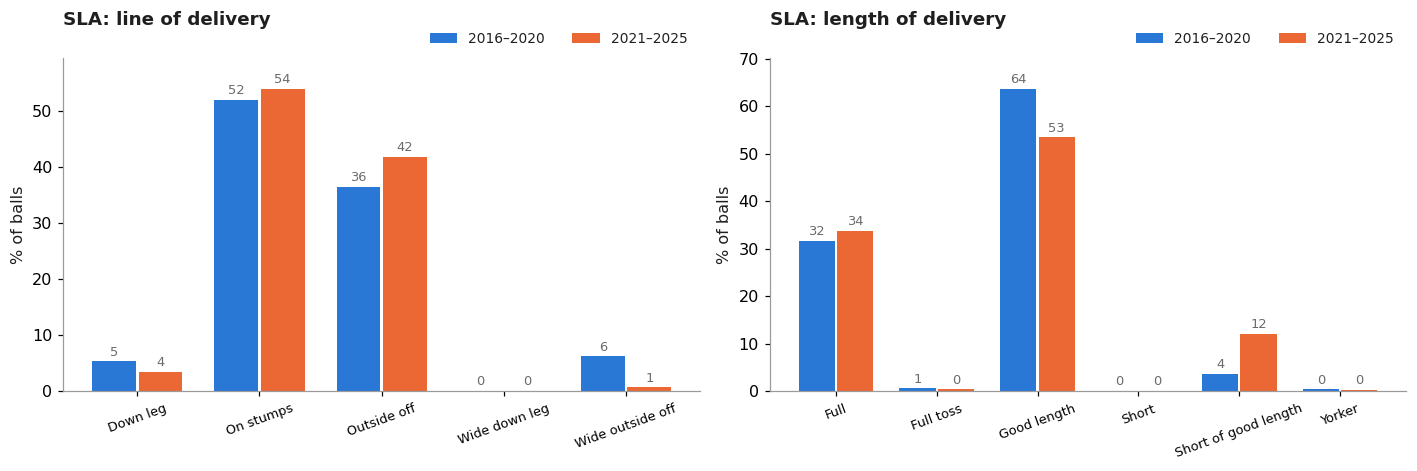

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
compare_bars(share_table(sla, "line").T, axes[0], "SLA: line of delivery")
compare_bars(share_table(sla, "length").T, axes[1], "SLA: length of delivery")
for ax in axes:
    ax.tick_params(axis="x", labelsize=8.5, rotation=20)
plt.tight_layout()
fig.savefig(FIG_DIR / "sla_line_length.png")
plt.show()

In [19]:
sla_ll = (sla.groupby(["period", "line", "length"])
             .agg(balls=("ballfaced", "sum"), runs=("batruns", "sum"),
                  dots=("batruns", lambda x: (x == 0).sum()),
                  fours=("batruns", lambda x: (x == 4).sum()),
                  sixes=("batruns", lambda x: (x == 6).sum()))
             .reset_index())
sla_ll["dot_pct"] = sla_ll["dots"] / sla_ll["balls"] * 100
sla_ll[sla_ll["balls"] >= 100].sort_values(["period", "balls"], ascending=[True, False]).set_index(["period", "line", "length"])

balls   runs  dots  fours  sixes  \
period    line             length                                          
2016–2020 ON_THE_STUMPS    GOOD_LENGTH  262.0  142.0   166      8      1   
          OUTSIDE_OFFSTUMP GOOD_LENGTH  217.0  111.0   151     12      0   
          ON_THE_STUMPS    FULL         158.0   96.0    98      9      0   
2021–2025 ON_THE_STUMPS    GOOD_LENGTH  185.0   35.0   155      0      0   
          OUTSIDE_OFFSTUMP GOOD_LENGTH  172.0   50.0   137      3      0   
          ON_THE_STUMPS    FULL         157.0   69.0   120      7      0   

                                        dot_pct  
period    line             length                
2016–2020 ON_THE_STUMPS    GOOD_LENGTH     63.4  
          OUTSIDE_OFFSTUMP GOOD_LENGTH     69.6  
          ON_THE_STUMPS    FULL            62.0  
2021–2025 ON_THE_STUMPS    GOOD_LENGTH     83.8  
          OUTSIDE_OFFSTUMP GOOD_LENGTH     79.7  
          ON_THE_STUMPS    FULL            76.4

In both periods, roughly 80% of SLA deliveries were **on the stumps or outside off**, and about 70% of those were good length or short of a good length. Every dismissal with recorded data fell inside these lines and lengths, so the wagon wheels below focus on them.

The three biggest line/length combinations all became harder to score from. On the stumps at a good length, his dot-ball percentage went from **63% to 84%**, and the boundaries disappeared.

## 8. Where did his runs go?

### 8.1 SLA on the stumps, good or full length

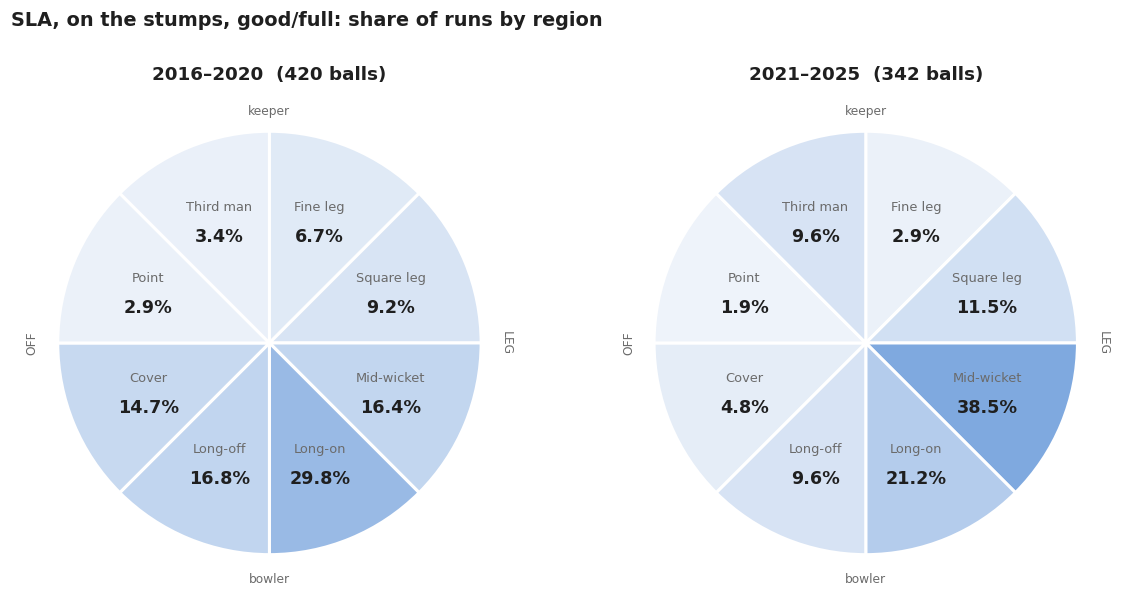

,2016–2020,2021–2025
wagonZone,,
Fine leg,6.7,2.9
Square leg,9.2,11.5
Mid-wicket,16.4,38.5
Long-on,29.8,21.2
Long-off,16.8,9.6
Cover,14.7,4.8
Point,2.9,1.9
Third man,3.4,9.6


In [20]:
sla_stumps = sla[(sla["line"] == "ON_THE_STUMPS") & sla["length"].isin(["GOOD_LENGTH", "FULL"])]
compare_wheels(sla_stumps, "runs", "SLA, on the stumps, good/full", "sla_on_stumps_runs.png")

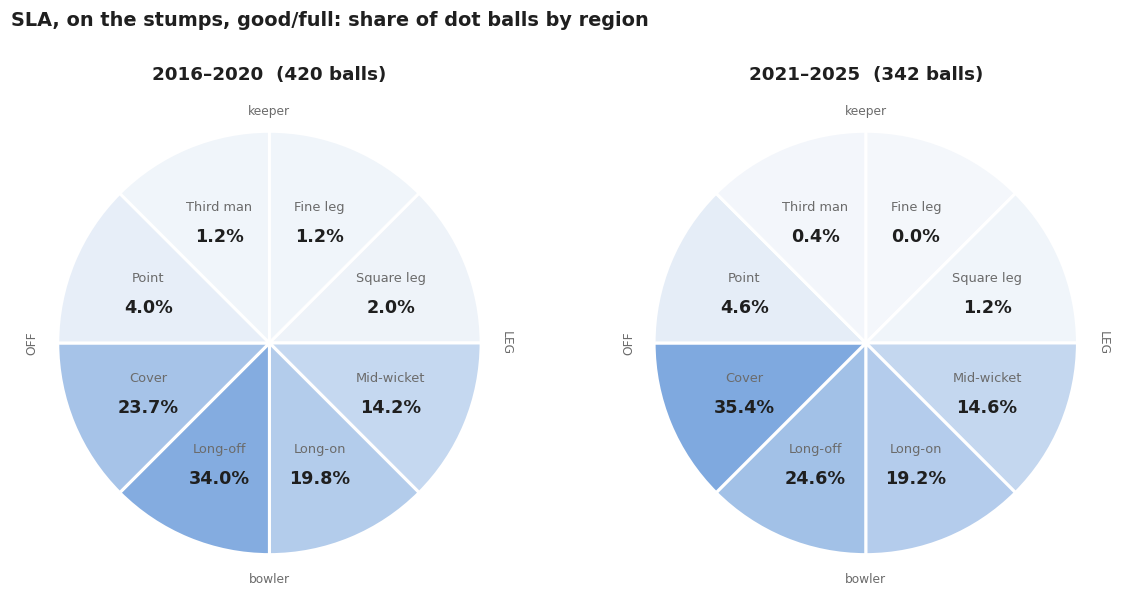

,2016–2020,2021–2025
wagonZone,,
Fine leg,1.2,0.0
Square leg,2.0,1.2
Mid-wicket,14.2,14.6
Long-on,19.8,19.2
Long-off,34.0,24.6
Cover,23.7,35.4
Point,4.0,4.6
Third man,1.2,0.4


In [21]:
compare_wheels(sla_stumps, "dots", "SLA, on the stumps, good/full", "sla_on_stumps_dots.png")

- In 2016–2020 he scored mostly **straight and through the off side**: long-on (29.8%), long-off (16.8%) and cover (14.7%) together made up about 61% of his runs.
- In 2021–2025 that fell to about 36%, and **mid-wicket more than doubled (16.4% → 38.5%)**. The scoring moved square on the leg side, mostly off flicks.
- **Cover turned into a dot-ball zone.** Its share of runs fell from 14.7% to 4.8%, while its share of dot balls rose from 23.7% to 35.4%.

### 8.2 SLA outside off stump, good length

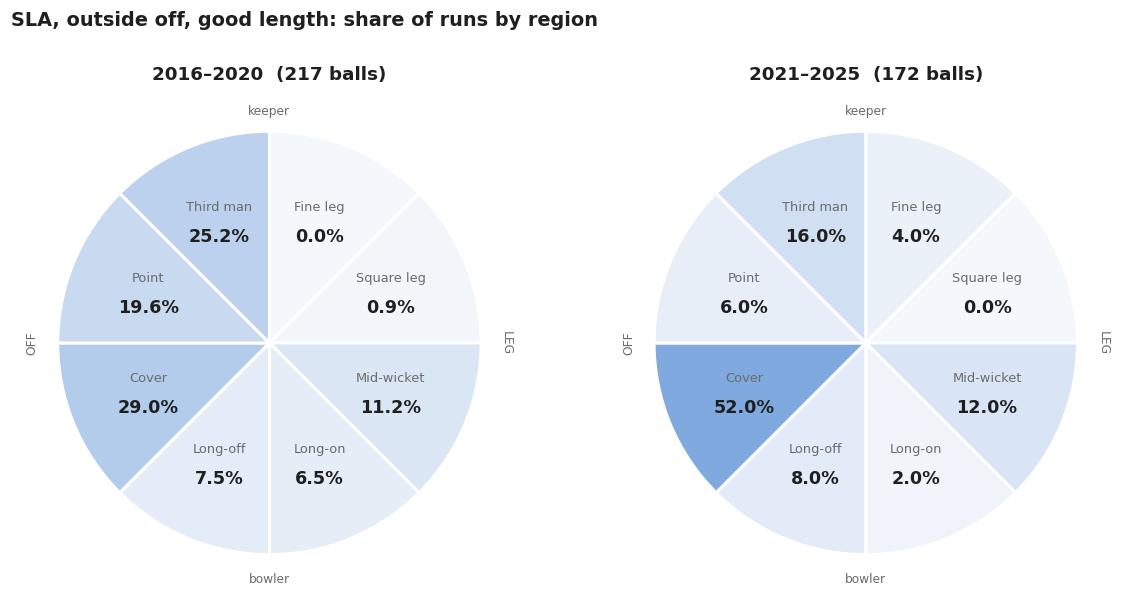

,2016–2020,2021–2025
wagonZone,,
Fine leg,0.0,4.0
Square leg,0.9,0.0
Mid-wicket,11.2,12.0
Long-on,6.5,2.0
Long-off,7.5,8.0
Cover,29.0,52.0
Point,19.6,6.0
Third man,25.2,16.0


In [22]:
sla_off = sla[(sla["line"] == "OUTSIDE_OFFSTUMP") & (sla["length"] == "GOOD_LENGTH")]
compare_wheels(sla_off, "runs", "SLA, outside off, good length", "sla_outside_off_runs.png")

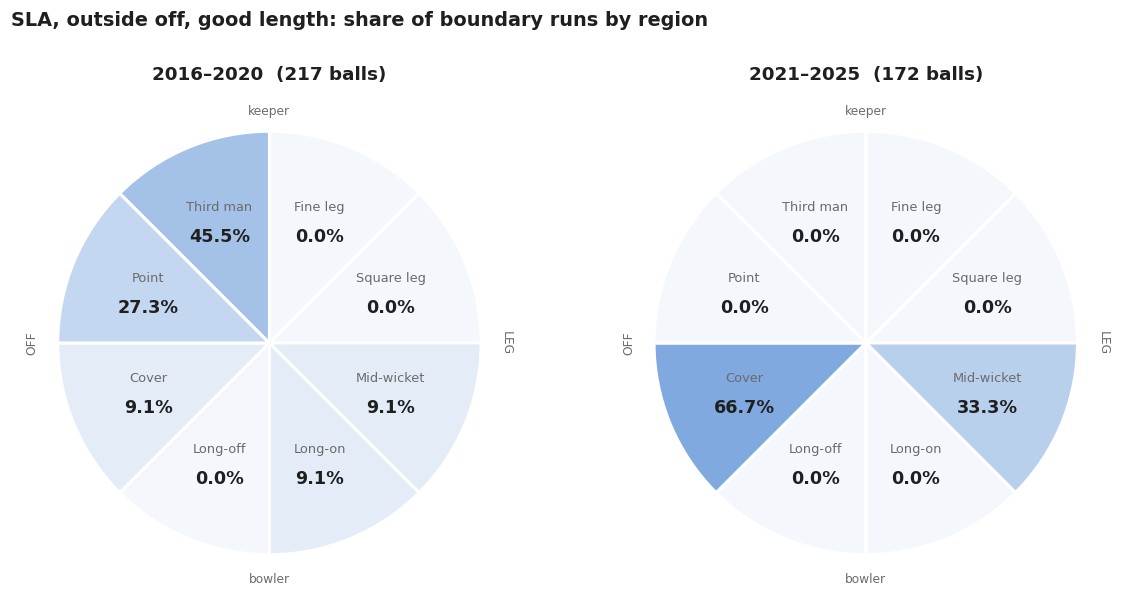

,2016–2020,2021–2025
wagonZone,,
Fine leg,0.0,0.0
Square leg,0.0,0.0
Mid-wicket,9.1,33.3
Long-on,9.1,0.0
Long-off,0.0,0.0
Cover,9.1,66.7
Point,27.3,0.0
Third man,45.5,0.0


In [23]:
compare_wheels(sla_off, "boundaries", "SLA, outside off, good length", "sla_outside_off_boundaries.png")

- In 2016–2020 his scoring outside off was spread around the off side, with a large share **behind square: point 19.6% and third man 25.2%**. Those two regions also produced about 73% of his boundary runs.
- In 2021–2025, point and third man together fell to 22%, and **cover took over at 52% of runs** (up from 29%). He hit only three fours in this category, so the boundary split is too small to read much into.
- Leg-side scoring stayed at about 18% in both periods.

So the same region played opposite roles depending on the line. **On the stumps, cover became a zone where he got stuck. Outside off, cover became his main scoring outlet.**

## 9. Shot composition by zone

Which shots was he playing into each region? This split uses good and full length balls from SLA, separated by line, because combining the two lines hid a real difference.

In [24]:
sla_gf = sla[sla["length"].isin(["GOOD_LENGTH", "FULL"])]
stumps_gf = sla_gf[sla_gf["line"] == "ON_THE_STUMPS"]
off_gf = sla_gf[sla_gf["line"] == "OUTSIDE_OFFSTUMP"]

print("On the stumps: main shots by region (>= 10% of balls)")
display(top_shots(stumps_gf, zones=[3, 4, 5, 6, 7]))
print("Outside off: main shots by region (>= 10% of balls)")
display(top_shots(off_gf, zones=[3, 4, 5, 6, 7]))

On the stumps: main shots by region (>= 10% of balls)


,2016–2020,2021–2025
Mid-wicket,"flick 52%, defended 36%","flick 61%, defended 36%"
Long-on,"on drive 52%, defended 36%","defended 57%, on drive 27%"
Long-off,"defended 48%, on drive 44%","defended 66%, on drive 22%"
Cover,"defended 61%, cover drive 31%","defended 81%, cover drive 10%"
Point,"defended 69%, steered 19%, cut shot 12%","defended 64%, push 29%"


Outside off: main shots by region (>= 10% of balls)


,2016–2020,2021–2025
Mid-wicket,"flick 56%, defended 37%","flick 60%, defended 40%"
Long-on,"defended 37%, on drive 37%, flick 11%","defended 40%, push 20%, straight drive 20%, fl..."
Long-off,"on drive 57%, defended 38%","on drive 44%, defended 41%"
Cover,"defended 45%, cover drive 34%, cut shot 10%","defended 54%, cover drive 26%, push 15%"
Point,"defended 42%, steered 30%, cut shot 22%","defended 46%, push 27%, cut shot 19%"


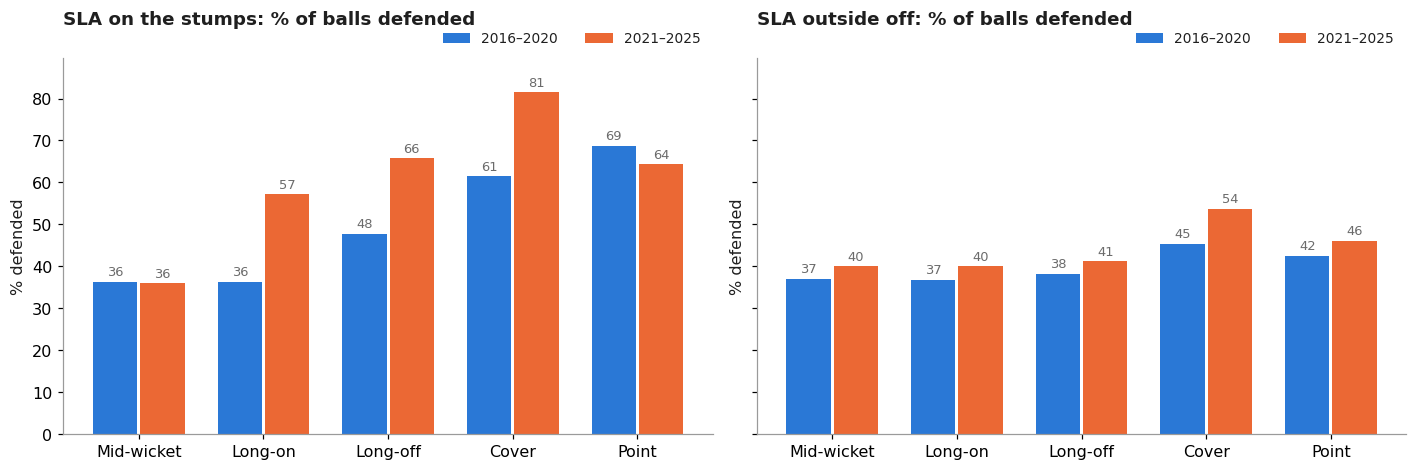

In [25]:
regions = ["Mid-wicket", "Long-on", "Long-off", "Cover", "Point"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True)
compare_bars(defended_share(stumps_gf).reindex(regions), axes[0],
             "SLA on the stumps: % of balls defended", ylabel="% defended")
compare_bars(defended_share(off_gf).reindex(regions), axes[1],
             "SLA outside off: % of balls defended", ylabel="% defended")
plt.tight_layout()
fig.savefig(FIG_DIR / "sla_defended_share.png")
plt.show()

- **On the stumps**, defended shots rose by **roughly 18–21 percentage points** in long-on, long-off and cover, and drives fell by the same amount. At point the defended share stayed about the same, but the cut disappeared and was replaced by a push.
- **Outside off**, the change was much smaller. He kept driving (on-drives down the ground, cover drives through cover), which is why his outside-off runs ended up concentrated at cover.

So the defensive shift was not a general habit against SLA. **It happened on the stumps.** It also matches the dismissal balls in 7.1: defending and flicking were not only how he got out, they had become his default against that line.

## 10. Did the pattern hold against every team?

First, home vs away, and the away countries with enough innings to compare:

In [26]:
home = kohli.assign(venue=np.where(kohli["country"] == "India", "Home", "Away"))
pd.concat({v: median_table(g) for v, g in home.groupby("venue")}, names=["venue"])

innings  median_runs  mean_runs  median_balls  median_sr
venue period                                                             
Away  2016–2020       38         31.0       46.6          64.5       45.7
      2021–2025       36         20.0       31.5          49.5       45.0
Home  2016–2020       31         45.0       77.7          65.0       60.4
      2021–2025       25         17.0       29.8          37.0       46.2

In [27]:
away = (kohli[kohli["country"] != "India"]
        .groupby(["country", "period", "p_match", "inns"])
        .agg(runs=("batruns", "sum"), balls=("ballfaced", "sum"))
        .reset_index())
away["sr"] = away["runs"] / away["balls"] * 100
(away.groupby(["country", "period"])
     .agg(innings=("runs", "size"), median_runs=("runs", "median"),
          median_balls=("balls", "median"), median_sr=("sr", "median"))
     .unstack("period"))

innings           median_runs           median_balls            \
period       2016–2020 2021–2025   2016–2020 2021–2025    2016–2020 2021–2025   
country                                                                         
Australia          8.0       9.0        28.5       7.0         81.5      21.0   
Bangladesh         NaN       4.0         NaN      10.0          NaN      25.5   
England           10.0      13.0        50.0      20.0         82.0      40.0   
New Zealand        4.0       NaN         8.5       NaN         22.5       NaN   
South Africa       6.0       8.0        34.5      36.5         59.5      73.0   
Sri Lanka          4.0       NaN        27.5       NaN         56.5       NaN   
West Indies        6.0       2.0        26.5      98.5         53.5     194.0   

             median_sr            
period       2016–2020 2021–2025  
country                           
Australia         39.6      41.9  
Bangladesh         NaN      26.4  
England           56.7      45.2  
New Zealand       36.4       NaN  
South Africa      51.4      57.8  
Sri Lanka         47.4       NaN  
West Indies       47.8      50.2

**England** and **South Africa** are the two countries I compare. Australia also has 8 and 9 innings, but his 2021–2025 innings there were very short (median 21 balls), which leaves too little to compare an early-innings phase like for like. New Zealand, Sri Lanka, Bangladesh and West Indies have too few innings in one or both periods.

To compare like with like, I look only at the **start of each innings**. For England that is the first 40 balls, his median balls faced there in 2021–2025. For South Africa it is the first 60 balls, close to his 2016–2020 median of 59.5 balls there.

*Note on the window:* the rows in the data file are **not stored in ball order** (only about 10% of innings are; see the appendix). So the window uses `cur_bat_bf`, Kohli's running count of balls faced, rather than the position of a row in the file.

In [28]:
WINDOWS = {"England": 40, "South Africa": 60}
early = {c: first_n_balls(kohli[kohli["country"] == c], n) for c, n in WINDOWS.items()}

def early_summary(d):
    inns = (d.groupby(["period", "p_match", "inns"])
              .agg(runs=("batruns", "sum"), balls=("ballfaced", "sum"),
                   dots=("batruns", lambda x: (x == 0).sum()), out=("out", "any"))
              .reset_index())
    inns["dot_pct"] = inns["dots"] / inns["balls"] * 100
    off = d[d["line"].isin(["OUTSIDE_OFFSTUMP", "WIDE_OUTSIDE_OFFSTUMP"])]
    return pd.DataFrame({
        "innings": inns.groupby("period").size(),
        "median_runs": inns.groupby("period")["runs"].median(),
        "median_dot_pct": inns.groupby("period")["dot_pct"].median(),
        "dismissals": inns.groupby("period")["out"].sum(),
        "balls_outside_off": off.groupby("period").size(),
        "left_alone_pct": off.groupby("period")["shot"].apply(lambda s: (s == "LEFT_ALONE").mean() * 100),
    }).reindex(PERIODS)

pd.concat({f"{c} (first {WINDOWS[c]} balls)": early_summary(d) for c, d in early.items()})

innings  median_runs  median_dot_pct  \
                              period                                            
England (first 40 balls)      2016–2020       10         16.5            75.0   
                              2021–2025       13         14.0            77.5   
South Africa (first 60 balls) 2016–2020        6         26.0            72.1   
                              2021–2025        8         18.5            79.2   

                                         dismissals  balls_outside_off  \
                              period                                     
England (first 40 balls)      2016–2020           2                274   
                              2021–2025           7                326   
South Africa (first 60 balls) 2016–2020           3                183   
                              2021–2025           3                252   

                                         left_alone_pct  
                              period                     
England (first 40 balls)      2016–2020            28.8  
                              2021–2025            38.7  
South Africa (first 60 balls) 2016–2020            30.6  
                              2021–2025            44.0

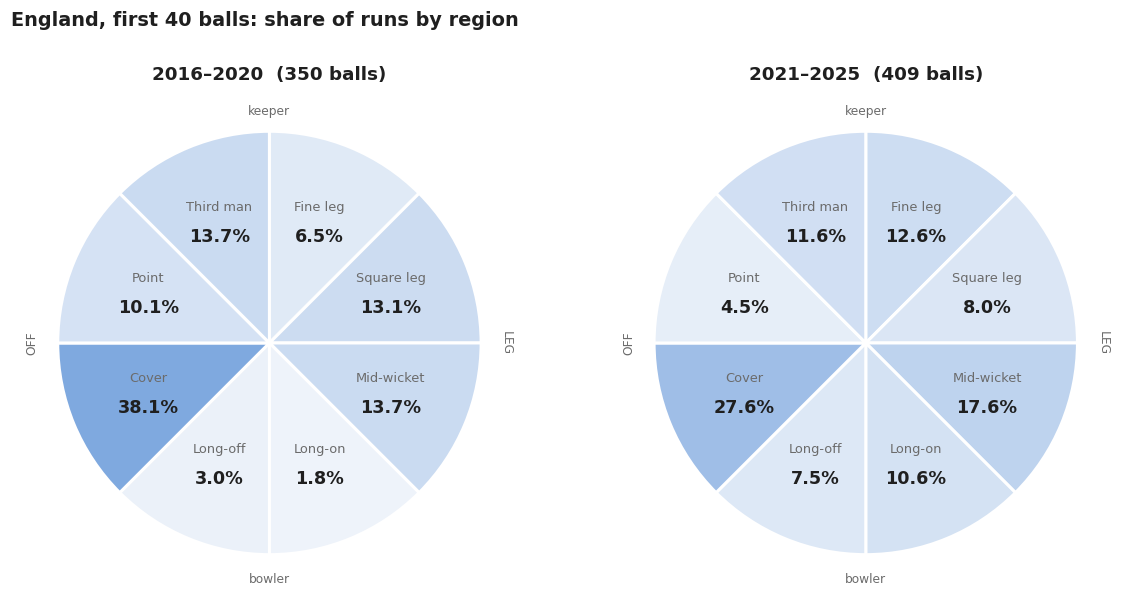

In [29]:
eng_wheel = compare_wheels(early["England"], "runs", "England, first 40 balls", "england_first40_runs.png")

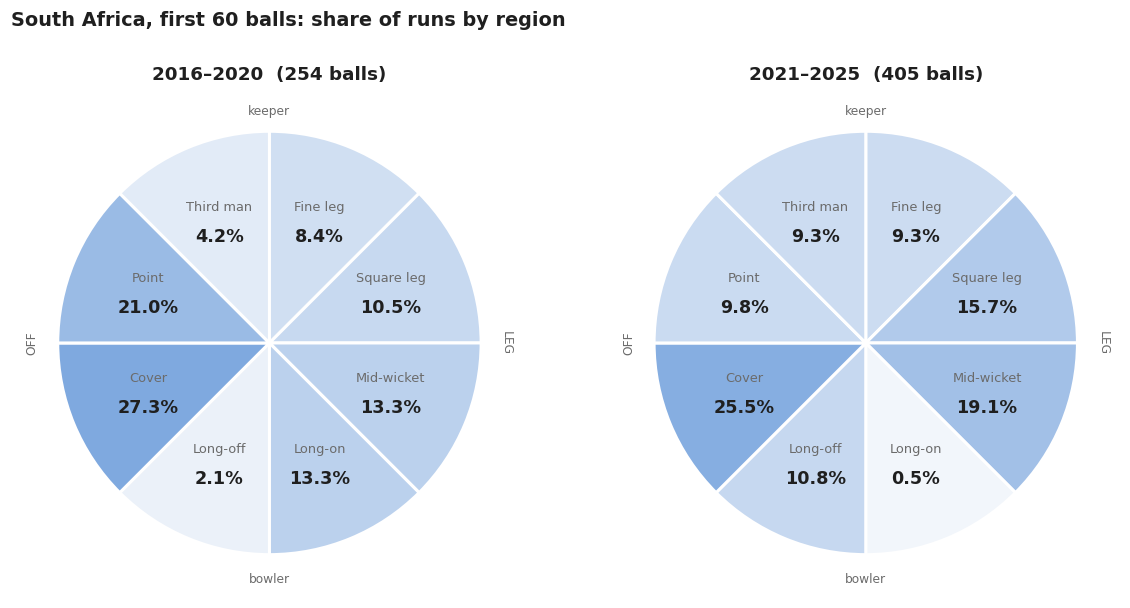

In [30]:
sa_wheel = compare_wheels(early["South Africa"], "runs", "South Africa, first 60 balls", "south_africa_first60_runs.png")

In [31]:
print("England: main shots through cover, point and third man")
display(top_shots(early["England"], zones=[6, 7, 8]))
print("South Africa: main shots through cover, point and third man")
display(top_shots(early["South Africa"], zones=[6, 7, 8]))

England: main shots through cover, point and third man


,2016–2020,2021–2025
Cover,"defended 52%, cover drive 38%","defended 40%, cover drive 27%, push 21%"
Point,"steered 38%, square drive 24%, defended 21%, p...","defended 35%, push 24%, steered 24%, square dr..."
Third man,"steered 43%, defended 29%, cover drive 21%","defended 33%, push 28%, steered 17%, left alon..."


South Africa: main shots through cover, point and third man


,2016–2020,2021–2025
Cover,"defended 67%, cover drive 25%","defended 49%, cover drive 25%, push 21%"
Point,"defended 50%, steered 27%","defended 39%, push 29%, square drive 13%"
Third man,"steered 60%, defended 40%","cover drive 40%, steered 20%, defended 10%, fl..."


Did England bowl more outside off to him, and how exactly was he getting out early in each country?

In [34]:
off_lines = ["OUTSIDE_OFFSTUMP", "WIDE_OUTSIDE_OFFSTUMP"]
for c, d in early.items():
    share = d.dropna(subset=["line"]).groupby("period")["line"].apply(lambda s: s.isin(off_lines).mean() * 100)
    print(c, "| % of balls outside off:", share.round(1).to_dict())
    outs = d[d["out"]]
    print(outs.groupby("period")[["line", "shot", "how_out"]].value_counts(), "\n")

England | % of balls outside off: {'2016–2020': 78.5, '2021–2025': 79.7}
period     line              shot         how_out
2016–2020  ON_THE_STUMPS     DEFENDED     caught     1
           OUTSIDE_OFFSTUMP  COVER_DRIVE  caught     1
2021–2025  OUTSIDE_OFFSTUMP  DEFENDED     caught     2
                             PUSH         caught     2
           ON_THE_STUMPS     DEFENDED     caught     1
           OUTSIDE_OFFSTUMP  LEFT_ALONE   bowled     1
                             ON_DRIVE     caught     1
Name: count, dtype: int64 

South Africa | % of balls outside off: {'2016–2020': 72.0, '2021–2025': 63.2}
period     line              shot         how_out          
2016–2020  OUTSIDE_OFFSTUMP  DEFENDED     leg before wicket    1
                             FLICK        leg before wicket    1
                             STEERED      caught               1
2021–2025  OUTSIDE_OFFSTUMP  COVER_DRIVE  caught               1
                             DEFENDED     caught               1
N

**England.** His leave percentage on balls outside off rose clearly, from 28.8% to 38.7%, but it didn't protect him. He was out inside his first 40 balls in **7 of 13 innings**, compared with 2 of 10 before. His median dot-ball percentage in that window rose from 75.0% to 77.5%, and median runs fell from 16.5 to 14.

This wasn't because England bowled more outside off. About 79–80% of his first 40 balls were outside off in both periods. What changed was how he got out. **Six of his seven early dismissals came on balls outside off**, and four of those were catches while he was defending or pushing, plus one bowled leaving the ball. Through the off side he also attacked less: fewer cover drives (38% → 27% of balls hit to cover) and far fewer steers behind square. He wasn't getting out to loose drives; he was getting out trying to defend.

**South Africa.** His leave percentage rose even more sharply, from 30.6% to 44.0%, even though South African bowlers actually bowled a smaller share outside off to him (72% → 63%), and here it seemed to work. He was out inside his first 60 balls in **3 of 8 innings**, compared with 3 of 6 before, so he got through the opening phase more often. (One of the three 2021–25 dismissals has no line or shot recorded, which is why the table above lists only two.) The cost was slower starts: median runs in the window fell from 26 to 18.5, and the dot-ball percentage rose from 72.1% to 79.2%. Because he survived that phase more often, his full-innings median in South Africa held up (34.5 → 36.5), while in England it fell from 50 to 20.

So the same adjustment, leaving more balls outside off, played out very differently. In South Africa it bought him time and the runs came later. In England, where the outside-off line stayed just as constant, he kept edging the balls he tried to defend. This data can't say *why* the two differed, but the difference itself is worth noting.

## 11. Conclusion and limitations

I expected one clean answer and found something more specific. His overall output fell sharply (median score 40 → 20), and the clearest, most consistent change was against **slow left-arm orthodox bowling**, not spin in general:

- **Same exposure, worse results.** He faced about the same number of SLA balls, yet his runs and strike rate dropped and his dismissals rose from 3 to 13.
- **Getting out differently.** The shots he was dismissed on moved from attacking (cuts at width) to defensive (defends and flicks on the stumps).
- **Scoring differently.** On the stumps, drives through long-on, long-off and cover gave way to defence, and his runs moved to mid-wicket. Outside off he kept driving, so his runs concentrated at cover, but his scoring behind square through point and third man halved.
- **Not a generally more cautious batter.** The defensive shift was specific to SLA on the stumps.

Against different oppositions the pattern was not uniform. In both England and South Africa he left far more balls outside off early in his innings. In South Africa that helped: he survived the opening phase more often and his full-innings median held up. In England it didn't: he was out inside his first 40 balls in 7 of 13 innings, and his median score there fell from 50 to 20.

**Limitations**
- Several findings rest on small counts. A rise from 3 to 13 dismissals is striking, but 13 is still a small number, and 5 of the 11 non-run-out SLA dismissals in 2021–2025 have no shot, line or length recorded.
- Shot labels describe direction, not intent or control. A "steered" ball to third man could be deliberate or a mistimed edge.
- The England and South Africa comparisons rest on only 10–13 and 6–8 innings respectively.
- No significance testing was run, so these patterns are strong directional evidence, not statistical proof.

## Appendix: data checks

Two things in the raw file would quietly distort the results if they weren't handled:

1. **Rows are not in ball order.** Within most innings the deliveries are not stored in the order they were bowled, so anything that counts "the first N balls" has to use `cur_bat_bf` (balls faced so far), not row position.
2. **Partner dismissals.** Some dismissal rows belong to the non-striker (see section 2).

The cell below checks the row order and lists every Kohli dismissal in England and South Africa with his score and balls faced at the time, so they can be compared with the real scorecards (for example, 0 off 1 at The Oval in 2018).


In [32]:
k = kohli.copy()
k["bf"] = pd.to_numeric(k["cur_bat_bf"], errors="coerce")

in_order = k.groupby(["p_match", "inns"])["bf"].apply(lambda s: s.is_monotonic_increasing)
print("Share of innings with rows in ball order:", round(in_order.mean(), 3))

for c, n in WINDOWS.items():
    outs = k[(k["country"] == c) & k["out"]]
    print(f"\n{c}: dismissals within first {n} balls (by cur_bat_bf):",
          outs[outs["bf"] <= n].groupby("period").size().to_dict())
    display(outs[["period", "date", "cur_bat_runs", "bf", "how_out"]].sort_values("date"))

Share of innings with rows in ball order: 0.1

England: dismissals within first 40 balls (by cur_bat_bf): {'2016–2020': 2, '2021–2025': 7}


,period,date,cur_bat_runs,bf,how_out
1133488,2016–2020,2018-08-01,51.0,93.0,leg before wicket
1133628,2016–2020,2018-08-01,149.0,225.0,caught
1131250,2016–2020,2018-08-09,17.0,29.0,caught
1131377,2016–2020,2018-08-09,23.0,57.0,caught
1129626,2016–2020,2018-08-18,103.0,197.0,leg before wicket
1130012,2016–2020,2018-08-18,97.0,152.0,caught
1128415,2016–2020,2018-08-30,46.0,71.0,caught
1128647,2016–2020,2018-08-30,58.0,130.0,caught
1126140,2016–2020,2018-09-07,0.0,1.0,caught
1126336,2016–2020,2018-09-07,49.0,70.0,caught



South Africa: dismissals within first 60 balls (by cur_bat_bf): {'2016–2020': 3, '2021–2025': 3}


,period,date,cur_bat_runs,bf,how_out
1171409,2016–2020,2018-01-05,28.0,40.0,leg before wicket
1171654,2016–2020,2018-01-05,5.0,13.0,caught
1170107,2016–2020,2018-01-13,153.0,217.0,caught
1170276,2016–2020,2018-01-13,5.0,20.0,leg before wicket
1166806,2016–2020,2018-01-24,41.0,79.0,bowled
1167461,2016–2020,2018-01-24,54.0,106.0,caught
1284029,2021–2025,2021-12-26,35.0,94.0,caught
1284414,2021–2025,2021-12-26,18.0,32.0,caught
1439225,2021–2025,2022-01-11,79.0,201.0,caught
1439824,2021–2025,2022-01-11,29.0,143.0,caught
